# Introduction

In [1]:
# importing all necessary libraries
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union
import geopandas as gpd
import pandas as pd
import numpy as np
import overturemaps

# Lab 4
## Challenge 1: ArcGIS Online Urban Heat Islands Tutorial

Link to my map: https://arcg.is/aL45u0
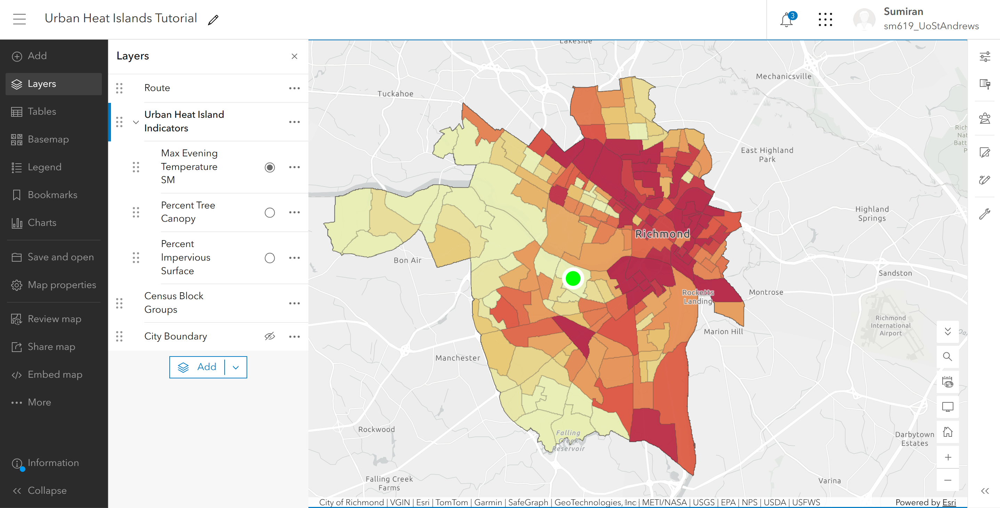

## Challenge 2: Choropleth 

Now is the time for you to create some choropleth maps.

Go to this portal https://www.spatialdata.gov.scot/geonetwork/srv/eng/catalog.search#/home
Get the Scottish Index of Multiple Deprivation (SIMD) 2020 dataset and extract the data only for the city of Edinburgh.
Create two static choropleth maps (e.g. matplotlib). These maps should represent an attribute you find interesting in the SIMD dataset. Using two different classifier methods, you need to show how the maps appear different even though the data and attributes are the same. Include a clear description of your choice and the difference in the classification method for the attribute chosen (e.g. Plotting histograms with breakpoints(bins)). You can find a complete list of classifiers at https://pysal.org/mapclassify/api.html.
Finally, create other two interactive maps (e.g. choropleth_map) - one for Glasgow and one for Edinburgh - to represent the difference in deprivation for both cities. Pick any of the available attributes., what is relevant is you can visualise how different both scottish cities are.
As always include the appropriate descriptions and code comments where you describe how you are processing the data and the insights you get from the results. Avoid to use AI for this, as the challenges are part of submitted work, and it is really easy to detect if you are using AI to generate the code or the comments, you will be reported for academic misconduct.

In [2]:
# importing the necessary libraries and files
import plotly.express as px
import geopandas as gpd
import mapclassify as mc
import matplotlib.pyplot as plt
import folium
import seaborn as sns

In [3]:
shapefile_path = 'lab4_data/SG_SIMD_2020.shp'
simd = gpd.read_file(shapefile_path)
simd

,DataZone,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
0,S01006506,Culter - 01,Aberdeen City,894,580,4691,4,7,14,68,...,125,4664.0,87,10,10%,1%,3248.0,11801.872345,4.388802e+06,"POLYGON ((383285.265 800510.607, 383348.492 80..."
1,S01006507,Culter - 02,Aberdeen City,793,470,4862,4,7,14,70,...,128,4602.0,85,4,10%,0%,3486.0,2900.406362,2.217468e+05,"POLYGON ((383527.919 801536.276, 383541.089 80..."
2,S01006508,Culter - 03,Aberdeen City,624,461,5686,5,9,17,82,...,130,4563.5,31,8,5%,1%,5342.0,3468.761949,2.701948e+05,"POLYGON ((383473.000 801227.000, 383597.000 80..."
3,S01006509,Culter - 04,Aberdeen City,537,307,4332,4,7,13,63,...,75,5626.0,42,6,7%,1%,4394.5,1647.461389,9.625426e+04,"POLYGON ((383976.659 801182.579, 383984.102 80..."
4,S01006510,Culter - 05,Aberdeen City,663,415,3913,3,6,12,57,...,168,3885.0,50,7,9%,1%,3736.0,3026.111412,1.800766e+05,"POLYGON ((384339.000 801211.000, 384316.510 80..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6971,S01013477,Broxburn South - 06,West Lothian,612,355,2464,2,4,8,36,...,217,3161.0,93,10,15%,2%,1671.0,1775.782199,1.098816e+05,"POLYGON ((308686.000 672220.000, 308688.000 67..."
6972,S01013478,Broxburn East - 01,West Lothian,817,582,3681,3,6,11,53,...,350,1819.0,87,1,10%,0%,3594.0,2319.192976,1.243817e+05,"POLYGON ((307423.889 672579.756, 307424.594 67..."
6973,S01013479,Broxburn East - 02,West Lothian,785,479,1423,2,3,5,21,...,560,795.0,96,9,12%,1%,2624.0,3234.544766,2.671458e+05,"POLYGON ((308478.000 672440.000, 308485.000 67..."
6974,S01013480,Broxburn East - 03,West Lothian,677,410,3291,3,5,10,48,...,106,5007.0,107,1,16%,0%,1865.0,1598.577583,9.624701e+04,"POLYGON ((308734.000 672598.000, 308743.000 67..."


In [4]:
# creatin a new data frame with just edinburgh data
edi = simd[simd["LAName"] == "City of Edinburgh"]
edi

,DataZone,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
1911,S01008417,Balerno and Bonnington Village - 01,City of Edinburgh,708,397,5537,4,8,16,80,...,86,5392.0,17,8,2%,1%,6350.0,20191.721420,1.029993e+07,"POLYGON ((315157.369 666212.846, 315173.727 66..."
1912,S01008418,Balerno and Bonnington Village - 02,City of Edinburgh,691,378,6119,5,9,18,88,...,103,5063.0,7,10,1%,1%,6650.0,25944.861787,2.357050e+07,"POLYGON ((317816.000 666579.000, 318243.000 66..."
1913,S01008419,Balerno and Bonnington Village - 03,City of Edinburgh,541,338,5200,4,8,15,75,...,187,3594.0,30,0,6%,0%,5372.5,5738.935106,1.366457e+06,"POLYGON ((316831.000 667049.000, 316816.000 66..."
1914,S01008420,Balerno and Bonnington Village - 04,City of Edinburgh,466,274,6431,5,10,19,93,...,109,4957.0,2,0,0%,0%,6957.0,1890.096713,1.051967e+05,"POLYGON ((316368.000 666124.000, 316379.297 66..."
1915,S01008421,Balerno and Bonnington Village - 05,City of Edinburgh,884,537,3441,3,5,10,50,...,264,2575.0,61,6,7%,1%,4598.0,2645.609037,1.465441e+05,"POLYGON ((316411.427 666596.771, 316422.940 66..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2503,S01009009,Queensferry West - 01,City of Edinburgh,476,287,1664,2,3,5,24,...,532,889.0,73,9,15%,2%,1634.0,2484.606370,2.103935e+05,"POLYGON ((312347.900 678734.500, 312360.900 67..."
2504,S01009010,Queensferry West - 02,City of Edinburgh,977,664,6263,5,9,18,90,...,62,5919.0,59,12,6%,1%,4957.0,2549.606615,2.057121e+05,"POLYGON ((312171.000 678341.000, 312169.000 67..."
2505,S01009011,Queensferry West - 03,City of Edinburgh,880,608,6568,5,10,19,95,...,46,6251.0,27,4,3%,0%,6314.0,1737.741513,1.532330e+05,"POLYGON ((312230.668 678036.110, 312230.927 67..."
2506,S01009012,Queensferry West - 04,City of Edinburgh,760,495,6610,5,10,19,95,...,80,5538.0,28,11,4%,1%,5722.0,1694.365106,1.192453e+05,"POLYGON ((311767.000 678043.000, 311798.000 67..."


In [5]:
# setting the index to the DataZone column
edi.set_index('DataZone', inplace=True)
edi.head()

,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,IncRate,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
DataZone,,,,,,,,,,,,,,,,,,,,,
S01008417,Balerno and Bonnington Village - 01,City of Edinburgh,708,397,5537,4,8,16,80,5%,...,86,5392.0,17,8,2%,1%,6350.0,20191.721420,1.029993e+07,"POLYGON ((315157.369 666212.846, 315173.727 66..."
S01008418,Balerno and Bonnington Village - 02,City of Edinburgh,691,378,6119,5,9,18,88,2%,...,103,5063.0,7,10,1%,1%,6650.0,25944.861787,2.357050e+07,"POLYGON ((317816.000 666579.000, 318243.000 66..."
S01008419,Balerno and Bonnington Village - 03,City of Edinburgh,541,338,5200,4,8,15,75,5%,...,187,3594.0,30,0,6%,0%,5372.5,5738.935106,1.366457e+06,"POLYGON ((316831.000 667049.000, 316816.000 66..."
S01008420,Balerno and Bonnington Village - 04,City of Edinburgh,466,274,6431,5,10,19,93,2%,...,109,4957.0,2,0,0%,0%,6957.0,1890.096713,1.051967e+05,"POLYGON ((316368.000 666124.000, 316379.297 66..."
S01008421,Balerno and Bonnington Village - 05,City of Edinburgh,884,537,3441,3,5,10,50,10%,...,264,2575.0,61,6,7%,1%,4598.0,2645.609037,1.465441e+05,"POLYGON ((316411.427 666596.771, 316422.940 66..."


In [6]:
# setting the CRS to the geographical coordinate system
edi = edi.to_crs(4326)
print(edi.crs, edi.total_bounds)

EPSG:4326 [-3.44952948 55.81879135 -3.07768062 56.01217035]


### Choosing classification methods

I used 5 classes and chose Fisher Jenks and Equal Interval as the classification methods to analyse CrimeCount data in Edinburgh. The Fisher Jenks method maximises difference in group means between groups while minimising within-group variance. The Equal Interval method divides data into equal intervals. In terms of the visual output, the Fisher Jenks method produces more variation in terms of which data zones are part of each cluster. There are clearly more data zones included in the lowest interval when using Equal Interval. When using Fisher Jenks, those same data zones are classified among more intervals (the blue, turquoise, and light green clusters) than with the Equal Interval method, which places most data zones in the same interval. Both maps show that crime is most concentrated in the city centre, and the Fisher Jenks map shows instances of crime in data zones on the outskirts of the city as well.

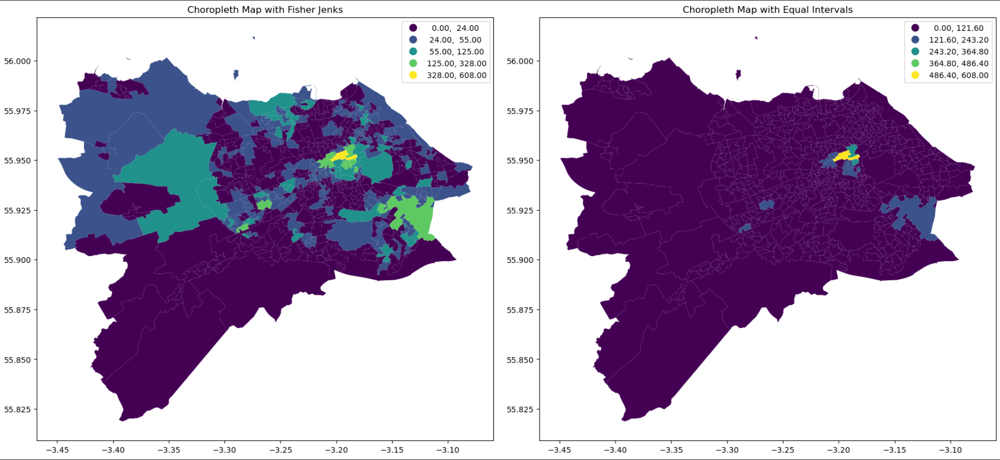

In [7]:
# Number of classes for classification
num_classes = 5

# Using Fisher Jenks classification
classifier_fj = mc.FisherJenks(edi['CrimeCount'], k=num_classes)
print(classifier_fj)
print(min(classifier_fj.bins), max(classifier_fj.bins))
print(classifier_fj.bins) 

# Using Equal Interval classification
classifier_ei = mc.EqualInterval(edi['CrimeCount'], k=num_classes)
print(classifier_ei)
print(min(classifier_ei.bins), max(classifier_ei.bins))
print(classifier_ei.bins)

FisherJenks

    Interval       Count
------------------------
[  0.00,  24.00] |   361
( 24.00,  55.00] |   173
( 55.00, 125.00] |    52
(125.00, 328.00] |    10
(328.00, 608.00] |     1
24.0 608.0
[ 24.  55. 125. 328. 608.]
EqualInterval

    Interval       Count
------------------------
[  0.00, 121.60] |   585
(121.60, 243.20] |     9
(243.20, 364.80] |     2
(364.80, 486.40] |     0
(486.40, 608.00] |     1
121.6 608.0
[121.6 243.2 364.8 486.4 608. ]


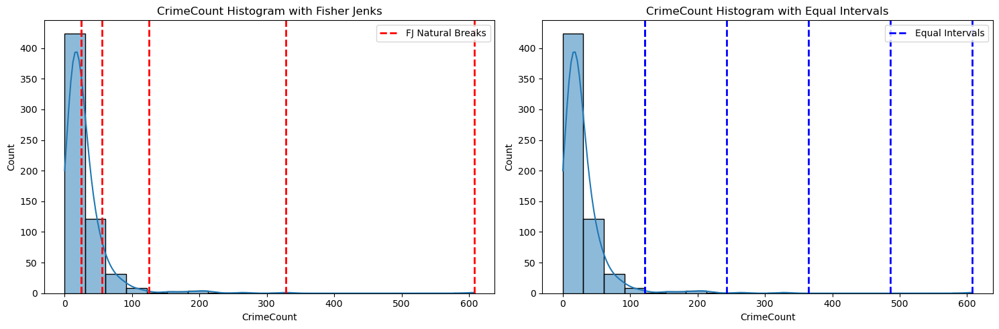

In [8]:
# creating two plots to compare how the two classification methods group data in histograms
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=edi, x="CrimeCount", ax=axes[0], kde=True, bins=20)
axes[0].axvline(classifier_fj.bins[0], color='red', linestyle='dashed', linewidth=2, label='FJ Natural Breaks')
for bin_value in classifier_fj.bins:
    axes[0].axvline(bin_value, color='red', linestyle='dashed', linewidth=2)
axes[0].set_title("CrimeCount Histogram with Fisher Jenks")
axes[0].legend()

# 3. The next plot using now ax=axes[1]
sns.histplot(data=edi, x="CrimeCount", ax=axes[1], kde=True, bins=20)
axes[1].axvline(classifier_ei.bins[0], color='blue', linestyle='dashed', linewidth=2, label='Equal Intervals')
for bin_value in classifier_ei.bins:
    axes[1].axvline(bin_value, color='blue', linestyle='dashed', linewidth=2)
axes[1].set_title("CrimeCount Histogram with Equal Intervals")
axes[1].legend()

# 4. Adjust the plot.
plt.tight_layout()
plt.show()

### Static choropleth maps

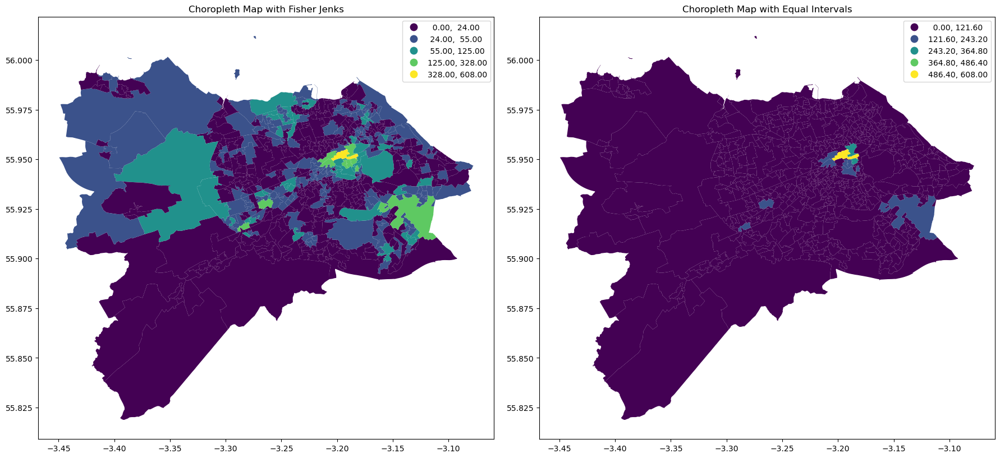

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8))

edi.plot(column='CrimeCount', ax=axs[0],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_fj.bins}
        )

axs[0].set_title("Choropleth Map with Fisher Jenks")

edi.plot(column='CrimeCount', ax=axs[1],
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins})

axs[1].set_title("Choropleth Map with Equal Intervals")

plt.tight_layout()
plt.show()

### Interactive choropleth maps

In [10]:
from shapely.geometry import Polygon
import requests
import pandas as pd
import geopandas as gpd
# isolating Glasgow data from the Scottish Government SIMD 2020 file
from shapely.geometry import Polygon
import requests
import pandas as pd
import geopandas as gpd

shapefile_path = 'lab4_data/SIMD_2020_GlasgowCity.shp'
glas = gpd.read_file(shapefile_path)
glas.head()

,DataZone,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
0,S01009758,Darnley East - 01,Glasgow City,624,407,4997,4,8,15,72,...,81,5523.0,73,43,13%,8%,1021.0,1474.152028,78490.309008,"POLYGON ((-4.32476 55.79910, -4.32574 55.79840..."
1,S01009759,Darnley East - 02,Glasgow City,860,570,161,1,1,1,3,...,561,791.0,223,29,24%,3%,494.0,2170.701472,136091.515542,"POLYGON ((-4.32823 55.81192, -4.32837 55.81166..."
2,S01009760,Darnley East - 03,Glasgow City,852,550,998,1,2,3,15,...,318,2079.0,173,8,19%,1%,1157.0,3057.747139,332345.088422,"POLYGON ((-4.32429 55.80524, -4.32408 55.80505..."
3,S01009761,Darnley East - 04,Glasgow City,846,558,3135,3,5,9,45,...,83,5459.0,122,24,13%,3%,1878.0,2761.244322,156078.015080,"POLYGON ((-4.32934 55.80065, -4.32952 55.80036..."
4,S01009762,Darnley East - 05,Glasgow City,1183,801,1247,1,2,4,18,...,340,1904.0,201,6,22%,1%,870.0,2295.018993,150737.851165,"POLYGON ((-4.33150 55.80660, -4.33145 55.80649..."


In [11]:
# setting the CRS to the geographic coordinate system
glas = glas.set_crs('epsg:4326')

In [12]:
# seeing the columns in the Glasgow data to determine what to map
glas.columns

Index(['DataZone', 'DZName', 'LAName', 'SAPE2017', 'WAPE2017', 'Rankv2',
       'Quintilev2', 'Decilev2', 'Vigintilv2', 'Percentv2', 'IncRate',
       'IncNumDep', 'IncRankv2', 'EmpRate', 'EmpNumDep', 'EmpRank', 'HlthCIF',
       'HlthAlcSR', 'HlthDrugSR', 'HlthSMR', 'HlthDprsPc', 'HlthLBWTPc',
       'HlthEmergS', 'HlthRank', 'EduAttend', 'EduAttain', 'EduNoQuals',
       'EduPartici', 'EduUniver', 'EduRank', 'GAccPetrol', 'GAccDTGP',
       'GAccDTPost', 'GAccDTPsch', 'GAccDTSsch', 'GAccDTRet', 'GAccPTGP',
       'GAccPTPost', 'GAccPTRet', 'GAccBrdbnd', 'GAccRank', 'CrimeCount',
       'CrimeRate', 'CrimeRank', 'HouseNumOC', 'HouseNumNC', 'HouseOCrat',
       'HouseNCrat', 'HouseRank', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='object')

In [13]:
# setting the index to DataZone
glas.set_index('DataZone', inplace=True)
glas.head()

,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,IncRate,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
DataZone,,,,,,,,,,,,,,,,,,,,,
S01009758,Darnley East - 01,Glasgow City,624,407,4997,4,8,15,72,3%,...,81,5523.0,73,43,13%,8%,1021.0,1474.152028,78490.309008,"POLYGON ((-4.32476 55.79910, -4.32574 55.79840..."
S01009759,Darnley East - 02,Glasgow City,860,570,161,1,1,1,3,45%,...,561,791.0,223,29,24%,3%,494.0,2170.701472,136091.515542,"POLYGON ((-4.32823 55.81192, -4.32837 55.81166..."
S01009760,Darnley East - 03,Glasgow City,852,550,998,1,2,3,15,23%,...,318,2079.0,173,8,19%,1%,1157.0,3057.747139,332345.088422,"POLYGON ((-4.32429 55.80524, -4.32408 55.80505..."
S01009761,Darnley East - 04,Glasgow City,846,558,3135,3,5,9,45,13%,...,83,5459.0,122,24,13%,3%,1878.0,2761.244322,156078.015080,"POLYGON ((-4.32934 55.80065, -4.32952 55.80036..."
S01009762,Darnley East - 05,Glasgow City,1183,801,1247,1,2,4,18,25%,...,340,1904.0,201,6,22%,1%,870.0,2295.018993,150737.851165,"POLYGON ((-4.33150 55.80660, -4.33145 55.80649..."


In [14]:
# Number of classes for classification
num_classes = 5

# Using Equal Interval classification
# Glasgow
classifier_nb_glas = mc.NaturalBreaks(glas['IncNumDep'], k=num_classes)
print(classifier_nb_glas)
print(min(classifier_nb_glas.bins), max(classifier_nb_glas.bins))
print(classifier_nb_glas.bins) 

# Edinburgh
classifier_nb_edi = mc.NaturalBreaks(edi['IncNumDep'], k=num_classes)
print(classifier_nb_edi)
print(min(classifier_nb_edi.bins), max(classifier_nb_edi.bins))
print(classifier_nb_edi.bins)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


NaturalBreaks

    Interval       Count
------------------------
[  0.00,  91.00] |   242
( 91.00, 174.00] |   196
(174.00, 249.00] |   146
(249.00, 336.00] |   121
(336.00, 656.00] |    41
91.0 656.0
[ 91. 174. 249. 336. 656.]
NaturalBreaks

    Interval       Count
------------------------
[  0.00,  40.00] |   265
( 40.00,  92.00] |   159
( 92.00, 158.00] |    91
(158.00, 251.00] |    63
(251.00, 405.00] |    19
40.0 405.0
[ 40.  92. 158. 251. 405.]


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


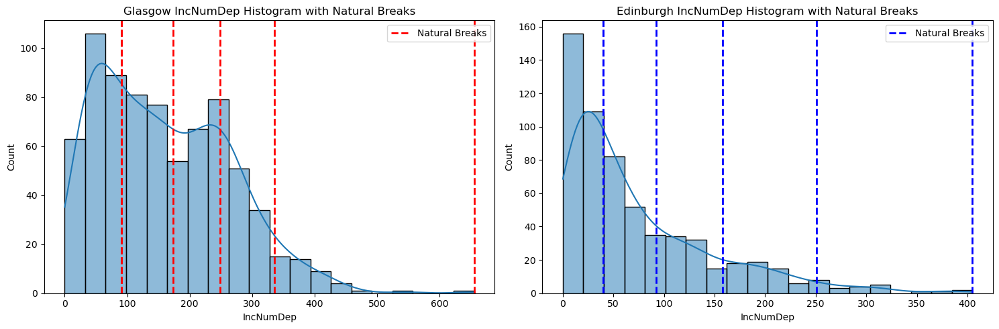

In [15]:
# 1. You know this already.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 2. Same as I explained before., but one extra property, ax=axes[0], which means it is a matrix of 1 row, two columns.
sns.histplot(data=glas, x="IncNumDep", ax=axes[0], kde=True, bins=20)
axes[0].axvline(classifier_nb_glas.bins[0], color='red', linestyle='dashed', linewidth=2, label='Natural Breaks')
for bin_value in classifier_nb_glas.bins:
    axes[0].axvline(bin_value, color='red', linestyle='dashed', linewidth=2)
axes[0].set_title("Glasgow IncNumDep Histogram with Natural Breaks")
axes[0].legend()

# 3. The next plot using now ax=axes[1]
sns.histplot(data=edi, x="IncNumDep", ax=axes[1], kde=True, bins=20)
axes[1].axvline(classifier_nb_edi.bins[0], color='blue', linestyle='dashed', linewidth=2, label='Natural Breaks')
for bin_value in classifier_nb_edi.bins:
    axes[1].axvline(bin_value, color='blue', linestyle='dashed', linewidth=2)
axes[1].set_title("Edinburgh IncNumDep Histogram with Natural Breaks")
axes[1].legend()

# 4. Adjust the plot.
plt.tight_layout()
plt.show()

In [16]:
num_classes = 5

classifier_nb_glas = mc.NaturalBreaks(glas['IncNumDep'], k=num_classes)
glas['classification_nb_glas'] = classifier_nb_glas.yb

glas[['IncNumDep', 'classification_nb_glas']]

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,IncNumDep,classification_nb_glas
DataZone,,
S01009758,20,0
S01009759,387,4
S01009760,194,2
S01009761,106,1
S01009762,299,3
...,...,...
S01010499,313,3
S01010500,324,3
S01010501,261,3


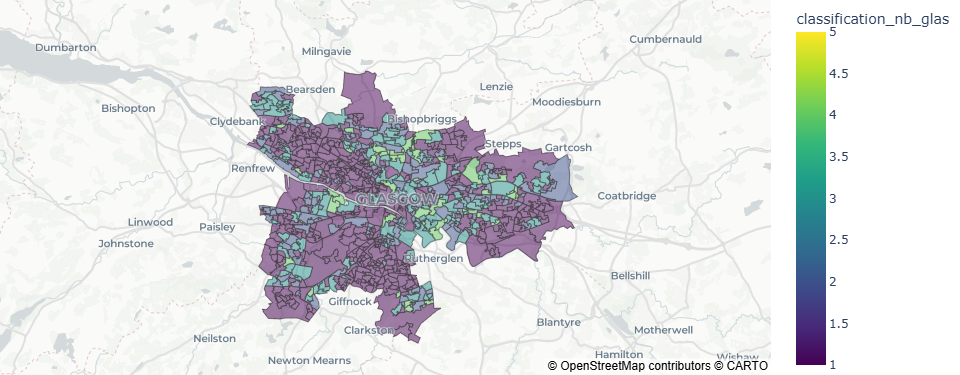

count    746.000000
mean     160.512064
std      104.359384
min        0.000000
25%       69.000000
50%      150.500000
75%      237.000000
max      656.000000
Name: IncNumDep, dtype: float64

In [17]:
fig_2 = px.choropleth_map(glas,
                           geojson=glas.geometry,
                           locations=glas.index,
                           color="classification_nb_glas",
                           color_continuous_scale="Viridis",
                           range_color= (1, 5),
                           opacity=0.5,
                           center={"lat": 55.866193, "lon": -4.258246},
                           map_style="carto-positron",
                           zoom=9.5)
fig_2.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig_2.show()
glas['IncNumDep'].describe()

In [18]:
num_classes = 5
classifier_nb_edi = mc.NaturalBreaks(edi['IncNumDep'], k=num_classes)
edi['classification_nb_edi'] = classifier_nb_edi.yb

edi[['IncNumDep', 'classification_nb_edi']]

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,IncNumDep,classification_nb_edi
DataZone,,
S01008417,32,0
S01008418,17,0
S01008419,29,0
S01008420,11,0
S01008421,91,1
...,...,...
S01009009,93,2
S01009010,38,0
S01009011,11,0


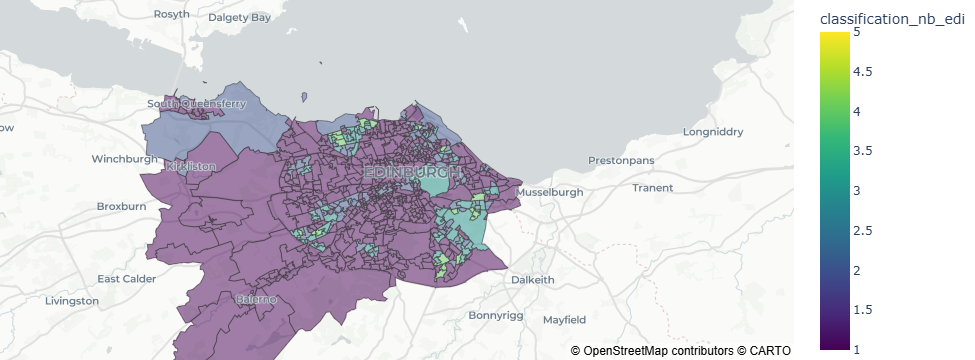

count    597.000000
mean      74.675042
std       73.555565
min        0.000000
25%       20.000000
50%       47.000000
75%      109.000000
max      405.000000
Name: IncNumDep, dtype: float64

In [19]:
fig_2 = px.choropleth_map(edi,
                           geojson=edi.geometry,
                           locations=edi.index,
                           color="classification_nb_edi",
                           color_continuous_scale="Viridis",
                           range_color= (1, 5),
                           opacity=0.5,
                           center={"lat": 55.947878, "lon":  -3.199850},
                           map_style="carto-positron",
                           zoom=9.5)
fig_2.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig_2.show()
edi['IncNumDep'].describe()

### Results and limitations

I compared IncNumDep (income deprivation in each data zone) in Edinburgh and Glasgow using a Natural Breaks classification method and found that there is much more variation in income deprivation in Glasgow, and the least deprived areas of Edinburgh are more clustered together in the north-west and eastern parts of the city. Overall, there are fewer income-deprived residents in Edinburgh based on comparison of the `edi['IncNumDep'].describe()` and `glas['IncNumDep'].describe()` tables: the minimum number if income-deprived residents for both cities is 0, but Glasgow has a maximum of 656 and a mean of 160.5, whereas Edinburgh has a maximum of 405 and mean of 74.6. However, Glasgow is more populous than Edinburgh and this analysis would likely benefit from percent of income-deprived residents rather than count-based data.

Limitation: it was difficult to find out what each of the column names actually meant and I eventually figured it out through the [Scottish Government](https://www.gov.scot/collections/scottish-index-of-multiple-deprivation-2020/) SIMD data site.